# Uncertainty quantification

iBART is a *selection* method, so its dominant uncertainty is **which descriptors
get chosen**, not just the spread around a fixed model. `jax_ibart.uncertainty`
provides honest, calibrated tools for this. We use a noisy synthetic problem
where only `a*b` drives the response (`c`, `d` are irrelevant).

In [1]:
import numpy as np
from jax_ibart import IBart, uncertainty

rng = np.random.default_rng(0)
n = 240
a, b, c, d = (rng.uniform(0.5, 2.0, n) for _ in range(4))
X = np.column_stack([a, b, c, d]); names = ["a", "b", "c", "d"]
y = 5.0 * (a * b) + rng.normal(0, 0.4, n)        # noisy

# a factory makes a fresh, identically-configured estimator on demand
factory = lambda: IBart(backend="diff", schedule=("b",), max_dim=1, seed=0, steps=900)

## 1. Conformal prediction intervals (honest, calibrated)

Split conformal wraps the **entire fit** (selection included) and calibrates on
held-out data, giving a finite-sample coverage guarantee even after selection.
We check the *realized* coverage on a fresh test set.

In [2]:
idx = rng.permutation(n); te, tr = idx[:80], idx[80:]
conf = uncertainty.conformal_intervals(factory, X[tr], y[tr], names,
                                       alpha=0.10, cal_frac=0.4, seed=0)
cov = uncertainty.empirical_coverage(conf, X[te], y[te])
print(f"target coverage: 0.90   realized: {cov:.2f}   half-width: {conf.half_width:.3f}")

target coverage: 0.90   realized: 0.85   half-width: 0.599


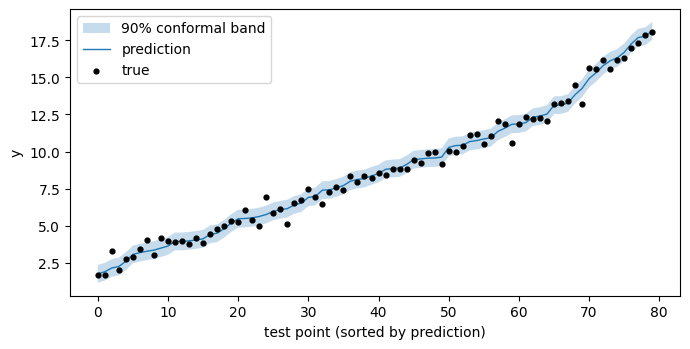

In [3]:
import matplotlib.pyplot as plt

lo, point, hi = conf.interval(X[te])
order = np.argsort(point)
fig, ax = plt.subplots(figsize=(7, 3.6))
xs = np.arange(len(order))
ax.fill_between(xs, lo[order], hi[order], alpha=0.25, label="90% conformal band")
ax.plot(xs, point[order], lw=1, label="prediction")
ax.scatter(xs, y[te][order], s=12, color="k", label="true", zorder=3)
ax.set_xlabel("test point (sorted by prediction)"); ax.set_ylabel("y")
ax.legend(); fig.tight_layout(); plt.show()

## 2. Selection stability

The most informative UQ for a selection method: how often is each feature chosen
across bootstrap resamples? The true drivers `a`, `b` should dominate.

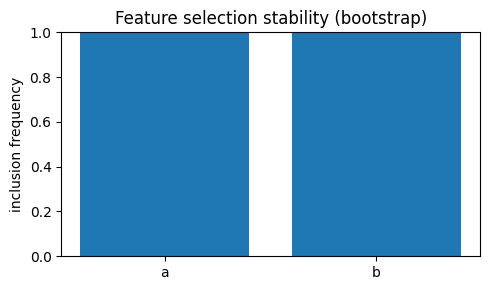

{'a': 1.0, 'b': 1.0}


In [4]:
stab = uncertainty.selection_stability(factory, X, y, names, n_boot=20, seed=0)
ff = stab["feature_freq"]
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(list(ff.keys()), list(ff.values()))
ax.set_ylabel("inclusion frequency"); ax.set_ylim(0, 1)
ax.set_title("Feature selection stability (bootstrap)")
fig.tight_layout(); plt.show()
print(ff)

## 3. Out-of-sample RMSE distribution

The papers' protocol: RMSE over many random train/test splits, as a distribution
rather than a single number.

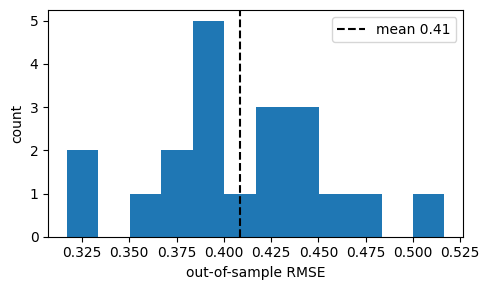

RMSE = 0.409 +/- 0.046  (90% CI [0.33, 0.47])


In [5]:
cv = uncertainty.repeated_split_rmse(factory, X, y, names, n_splits=20, seed=0)
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(cv["rmse"], bins=12)
ax.axvline(cv["mean"], color="k", ls="--", label=f"mean {cv['mean']:.2f}")
ax.set_xlabel("out-of-sample RMSE"); ax.set_ylabel("count"); ax.legend()
fig.tight_layout(); plt.show()
print(f"RMSE = {cv['mean']:.3f} +/- {cv['std']:.3f}  (90% CI [{cv['q05']:.2f}, {cv['q95']:.2f}])")

## 4. Coefficient intervals (classical, optimistic)

Classical OLS confidence intervals on the final model -- fast, but *optimistic*
because they condition on the selected descriptors and ignore selection. Use the
conformal intervals (section 1) for honest predictive coverage.

In [6]:
model = factory().fit(X, y, names)
ols = uncertainty.ols_intervals(model, X, y)
for term in ols["coefficients"]:
    print(f"{term['term']:>10}: {term['coef']:+.3f}  "
          f"[{term['ci_low']:+.3f}, {term['ci_high']:+.3f}]")

 intercept: +0.004  [-0.093, +0.101]
       a*b: +4.986  [+4.934, +5.038]


**Takeaway:** report the conformal band for honest prediction intervals and the
selection-stability frequencies to show which descriptors are trustworthy --
together they capture the uncertainty a single point estimate hides. See also
`uncertainty.bart_posterior_intervals` for Bayesian posterior predictive bands.